<a href="https://colab.research.google.com/github/mahalakshmiveeramani/Digitalportfolio/blob/main/Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Customer Churn Forecasting System**

**Import Libraries**

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

from sklearn.inspection import permutation_importance
import joblib
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded1 = files.upload()

Saving customer_churn_dataset-training-master.csv to customer_churn_dataset-training-master (1).csv


In [ ]:
uploaded2 = files.upload()

Saving customer_churn_dataset-testing-master(1).csv to customer_churn_dataset-testing-master(1).csv


**Load Dataset**

In [24]:
import pandas as pd

train_df = pd.read_csv(
    "customer_churn_dataset-training-master.csv"
)

test_df = pd.read_csv(
    "customer_churn_dataset-testing-master.csv"
)

print("Training Dataset Shape:", train_df.shape)

print("Testing Dataset Shape:", test_df.shape)

display(train_df.head())

display(test_df.head())

Training Dataset Shape: (440833, 12)
Testing Dataset Shape: (64374, 12)


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


**Understand Dataset**

In [25]:
print("Dataset Information")

train_df.info()

print("\nMissing Values")

print(train_df.isnull().sum())

print("\nDuplicate Values")

print(train_df.duplicated().sum())

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440833 entries, 0 to 440832
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         440832 non-null  float64
 1   Age                440832 non-null  float64
 2   Gender             440832 non-null  object 
 3   Tenure             440832 non-null  float64
 4   Usage Frequency    440832 non-null  float64
 5   Support Calls      440832 non-null  float64
 6   Payment Delay      440832 non-null  float64
 7   Subscription Type  440832 non-null  object 
 8   Contract Length    440832 non-null  object 
 9   Total Spend        440832 non-null  float64
 10  Last Interaction   440832 non-null  float64
 11  Churn              440832 non-null  float64
dtypes: float64(9), object(3)
memory usage: 40.4+ MB

Missing Values
CustomerID           1
Age                  1
Gender               1
Tenure               1
Usage Frequency      1

**Data Cleaning**

In [26]:
train = train_df.copy()

test = test_df.copy()

train = train.dropna(how="all")

test = test.dropna(how="all")

train = train.drop_duplicates()

test = test.drop_duplicates()

train = train.dropna(subset=["Churn"])

test = test.dropna(subset=["Churn"])

train["Churn"] = train["Churn"].astype(int)

test["Churn"] = test["Churn"].astype(int)

print("Data Cleaning Completed")

print("Training Shape:", train.shape)

print("Testing Shape:", test.shape)

Data Cleaning Completed
Training Shape: (440832, 12)
Testing Shape: (64374, 12)


**Feature engineering**

In [28]:
def add_features(data):

    data = data.copy()

    data["TenureGroup"] = pd.cut(
        data["Tenure"],
        bins=[-1, 12, 24, 36, 48, 60],
        labels=["0-12", "13-24", "25-36",
                "37-48", "49-60"]
    )

    data["SupportCallGroup"] = pd.cut(
        data["Support Calls"],
        bins=[-1, 2, 5, 10],
        labels=["Low", "Medium", "High"]
    )

    data["PaymentDelayGroup"] = pd.cut(
        data["Payment Delay"],
        bins=[-1, 5, 15, 30],
        labels=["Low", "Medium", "High"]
    )

    data["UsagePerTenure"] = (
        data["Usage Frequency"] /
        data["Tenure"].replace(0, np.nan)
    )

    return data


train = add_features(train)

test = add_features(test)

print("Feature Engineering Completed!")

display(train.head())

Feature Engineering Completed!


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn,TenureGroup,SupportCallGroup,PaymentDelayGroup,UsagePerTenure
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1,37-48,Medium,High,0.358974
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1,49-60,High,Medium,0.020408
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1,13-24,High,High,0.285714
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1,37-48,High,Medium,0.552632
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1,25-36,Medium,Medium,0.625000


**Exploratory Data Analysis(EDA)**

Churn Distribution

Churn Distribution
Churn
1    249999
0    190833
Name: count, dtype: int64


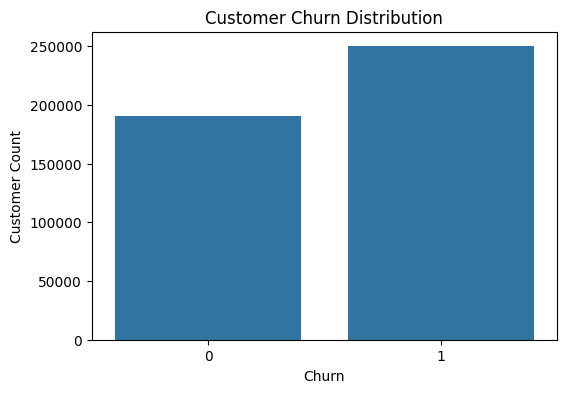

In [29]:
print("Churn Distribution")

print(train["Churn"].value_counts())

plt.figure(figsize=(6,4))

sns.countplot(data=train, x="Churn")

plt.title("Customer Churn Distribution")

plt.xlabel("Churn")

plt.ylabel("Customer Count")

plt.show()

Churn Percentage

In [30]:
churn_percentage = (
    train["Churn"].value_counts(normalize=True) * 100
)

print(churn_percentage.round(2))

Churn
1    56.71
0    43.29
Name: proportion, dtype: float64


**Contract Length Analysis**

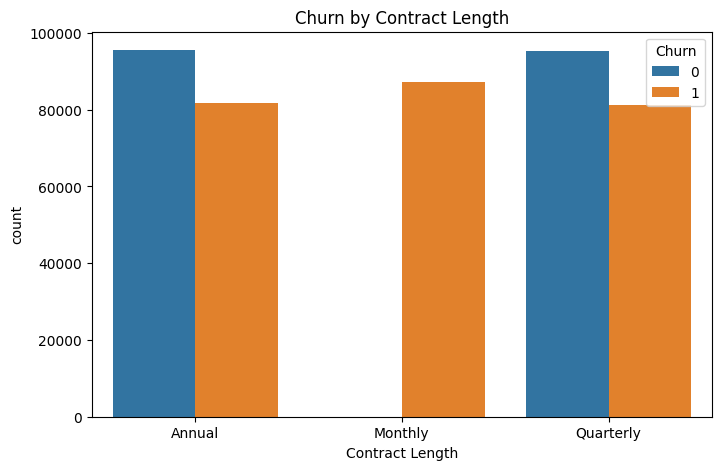

In [31]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=train,
    x="Contract Length",
    hue="Churn"
)

plt.title("Churn by Contract Length")

plt.show()

**Subscription Analysis**

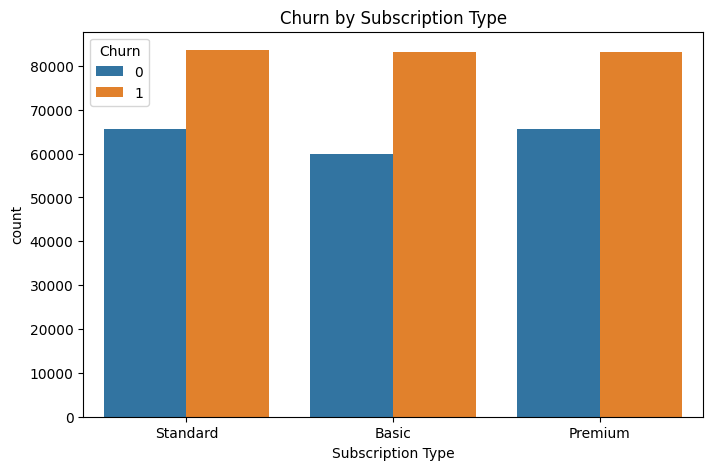

In [32]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=train,
    x="Subscription Type",
    hue="Churn"
)

plt.title("Churn by Subscription Type")

plt.show()

**Tenure Analysis**

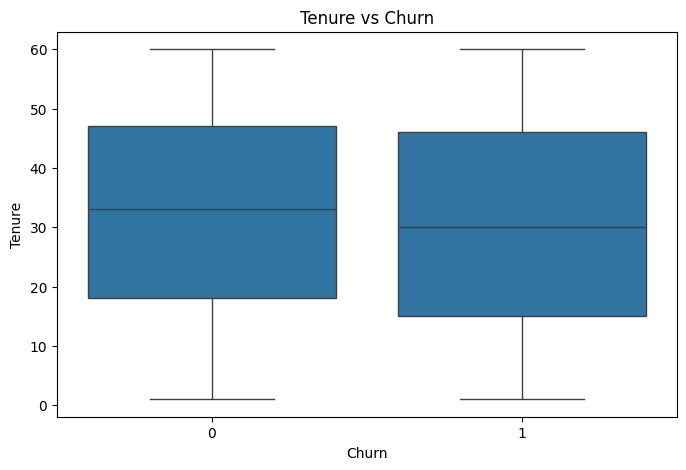

In [33]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=train,
    x="Churn",
    y="Tenure"
)

plt.title("Tenure vs Churn")

plt.show()

**Support Calls Analysis**

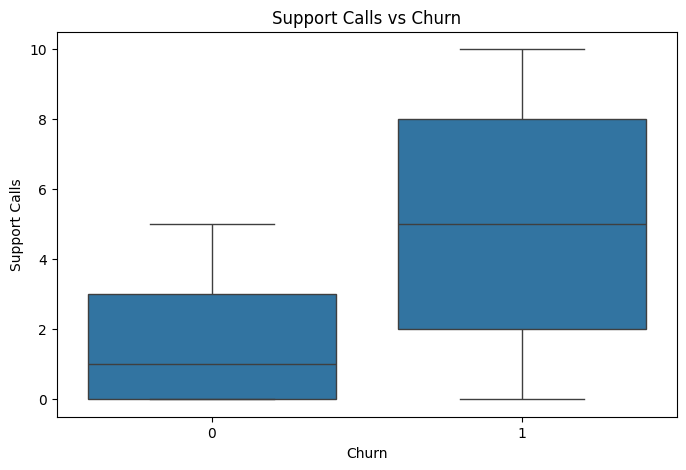

In [34]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=train,
    x="Churn",
    y="Support Calls"
)

plt.title("Support Calls vs Churn")

plt.show()

**Prepare Data for Machine Learning**

In [35]:
X_train = train.drop(
    columns=["Churn", "CustomerID"]
)

y_train = train["Churn"]

X_test = test.drop(
    columns=["Churn", "CustomerID"]
)

y_test = test["Churn"]

print("Training Features:", X_train.shape)

print("Testing Features:", X_test.shape)

Training Features: (440832, 14)
Testing Features: (64374, 14)


**Data Preprocessing**

In [36]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Data Preprocessing Completed!")

Data Preprocessing Completed!


**Model Training**

In [37]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=18,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )

}

trained_models = {}

results = []

for name, model in models.items():

    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)

    predictions = pipe.predict(X_test)

    probabilities = pipe.predict_proba(X_test)[:, 1]

    results.append({

        "Model": name,

        "Accuracy": accuracy_score(
            y_test, predictions
        ),

        "Precision": precision_score(
            y_test, predictions
        ),

        "Recall": recall_score(
            y_test, predictions
        ),

        "F1_Score": f1_score(
            y_test, predictions
        ),

        "ROC_AUC": roc_auc_score(
            y_test, probabilities
        )

    })

    trained_models[name] = pipe


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "ROC_AUC",
    ascending=False
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.5716,0.5256,0.9825,0.6848,0.7180
1,Random Forest,0.5038,0.4884,0.9984,0.6559,0.6372


**Confusion Matrix**

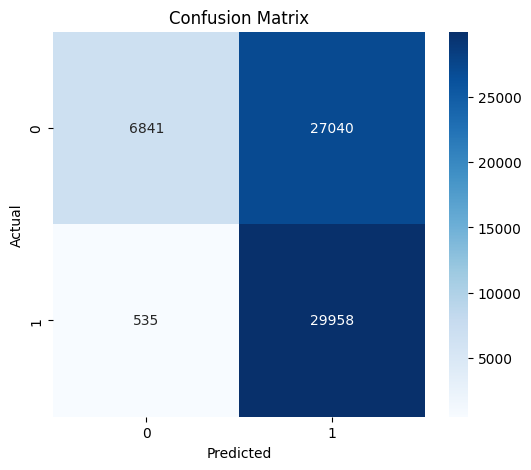

In [38]:
best_model = trained_models["Logistic Regression"]

predictions = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    predictions
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

**Classification Report**

In [39]:
print(
    classification_report(
        y_test,
        predictions,
        target_names=["Stayed", "Churned"]
    )
)

              precision    recall  f1-score   support

      Stayed       0.93      0.20      0.33     33881
     Churned       0.53      0.98      0.68     30493

    accuracy                           0.57     64374
   macro avg       0.73      0.59      0.51     64374
weighted avg       0.74      0.57      0.50     64374



**ROC Curve**

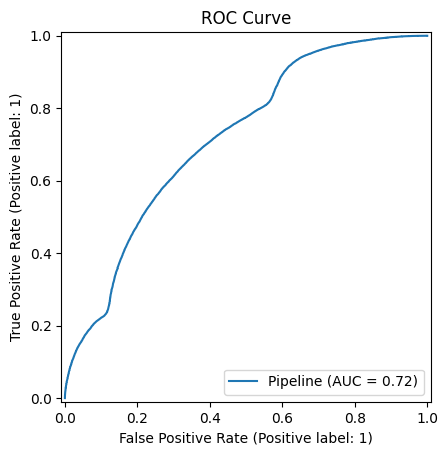

In [40]:
RocCurveDisplay.from_estimator(
    best_model,
    X_test,
    y_test
)

plt.title("ROC Curve")

plt.show()

**Feature Importance**

In [41]:
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

importance_df = pd.DataFrame({

    "Feature": X_test.columns,

    "Importance": importance.importances_mean

})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(10))

,Feature,Importance
5,Payment Delay,0.106964
11,SupportCallGroup,0.074301
4,Support Calls,0.029255
7,Contract Length,0.026347
8,Total Spend,0.010034
1,Gender,0.007146
0,Age,0.003277
3,Usage Frequency,0.001752
6,Subscription Type,0.000055
9,Last Interaction,-0.000071


**Graph**

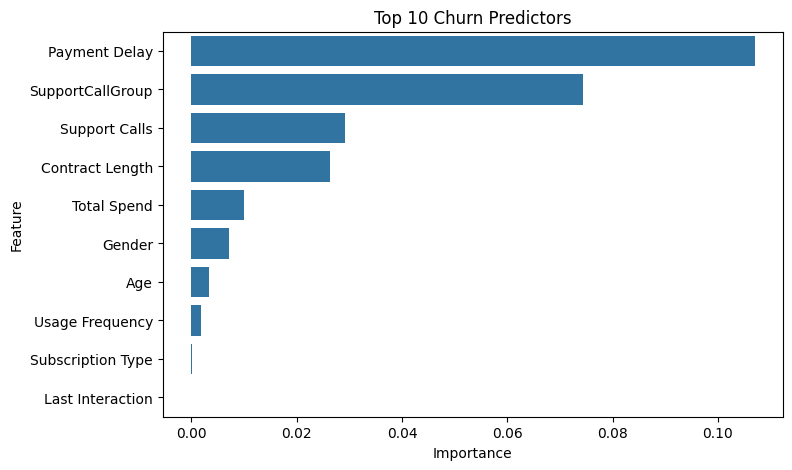

In [42]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Churn Predictors")

plt.show()

**Customer Churn Prediction**

In [43]:
probabilities = best_model.predict_proba(
    X_test
)[:, 1]

risk_output = pd.DataFrame()

risk_output["Actual_Churn"] = y_test.values

risk_output["Churn_Probability"] = probabilities

risk_output["Risk_Level"] = pd.cut(
    probabilities,
    bins=[-0.001, 0.35, 0.60, 1.0],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

print("Customer Risk Prediction")

display(risk_output.head(10))

Customer Risk Prediction


,Actual_Churn,Churn_Probability,Risk_Level
0,1,0.999999,High Risk
1,0,1.000000,High Risk
2,0,0.863046,High Risk
3,0,0.935535,High Risk
4,0,0.999992,High Risk
5,0,1.000000,High Risk
6,1,1.000000,High Risk
7,0,0.999999,High Risk
8,0,1.000000,High Risk
9,0,0.275438,Low Risk


**Bussiness Insights**

In [44]:
for col in [
    "Contract Length",
    "Subscription Type",
    "Gender"
]:

    print("\nChurn Analysis by", col)

    summary = train.groupby(
        col,
        observed=False
    )["Churn"].agg(
        ["count", "mean"]
    )

    summary["Churn_Percentage"] = (
        summary["mean"] * 100
    ).round(2)

    display(summary)


Churn Analysis by Contract Length


,count,mean,Churn_Percentage
Contract Length,,,
Annual,177198,0.460761,46.08
Monthly,87104,1.000000,100.00
Quarterly,176530,0.460256,46.03



Churn Analysis by Subscription Type


,count,mean,Churn_Percentage
Subscription Type,,,
Basic,143026,0.581782,58.18
Premium,148678,0.559417,55.94
Standard,149128,0.560700,56.07



Churn Analysis by Gender


,count,mean,Churn_Percentage
Gender,,,
Female,190580,0.666691,66.67
Male,250252,0.491269,49.13


****

**Save Project Files**

In [45]:
os.makedirs(
    "customer_churn_outputs",
    exist_ok=True
)

results_df.to_csv(
    "customer_churn_outputs/model_comparison.csv",
    index=False
)

importance_df.to_csv(
    "customer_churn_outputs/feature_importance.csv",
    index=False
)

risk_output.to_csv(
    "customer_churn_outputs/churn_predictions.csv",
    index=False
)

joblib.dump(
    best_model,
    "customer_churn_outputs/best_churn_model.pkl"
)

print("All Project Files Saved Successfully!")

All Project Files Saved Successfully!


**Final Project Conclusion**

Project Conclusion:

This project focuses on developing a Customer Churn Forecasting System using Machine Learning. The main objective is to identify customers who are likely to stop using a company's services.

Data cleaning, feature engineering, exploratory data analysis, data preprocessing and machine learning algorithms were implemented.

Logistic Regression and Random Forest models were trained and evaluated using Accuracy, Precision, Recall, F1-score and ROC-AUC metrics.

The project also identifies important churn-related factors and provides customer retention recommendations to help businesses improve customer satisfaction and reduce customer loss.